# SUSY_DRU · clasificadores de 2 y 3 qubits: costo local y global

El clasificador de la corrida final usa **un qubit**. Con un qubit, el costo local y el global coinciden; con dos ya son
distintos. Este notebook entrena clasificadores de **2 y 3 qubits** con las 7 variables, la receta de la corrida final y
5 semillas, y los compara con los modelos de un qubit de la corrida final. Es la base de la subsección 4.8.2 del informe.

Usa la misma estructura que `SUSY_DRU_7v8_PennyLane.ipynb`: clona el repo, verifica los datos y el split, guarda cada
corrida en Drive en cuanto termina, retoma si Colab se corta y tiene modo rápido y modo completo.

| Paso | Qué hace | Modo rápido | Modo completo |
|---|---|---|---|
| 0 | Configuración: modo, nombre del experimento, carpeta de Drive | | |
| 1 | Clona el repo, instala PennyLane 0.45.1 y monta Drive | 1 a 2 min | 1 a 2 min |
| 2 | Baja SUSY y verifica el split firmado (5000 / 1000 / 5000) | < 1 min | < 1 min |
| 3 | Diseño: 10 configuraciones y referencias de un qubit | segundos | segundos |
| 4 | Circuito de varios qubits en PennyLane, verificado contra `dru_core` | < 1 min | < 1 min |
| 5 | La receta reproduce la corrida final (1 qubit, infidelidad lineal, semilla 101) | ~1 min | ~1 min |
| 6 | Entrena las corridas y guarda cada una en Drive | ~4 min | ~2 h |
| 7 | Diagnóstico del gradiente con la inicialización del entrenamiento | segundos | < 2 min |
| 8 | Evaluación en prueba y comparaciones (DeLong + Holm) | < 1 min | < 1 min |
| 9 | Gráficas | < 1 min | < 1 min |
| 10 | Resumen de archivos y equivalencias con la corrida final | | |

### El experimento

| Qubits | Capas (L) | Costo | Lectura | Pérdidas | Parámetros |
|---|---|---|---|---|---|
| 2 | 5 | local | ⟨Z₀⟩ | infidelidad lineal, infidelidad cuadrática, BCE | 140 |
| 2 | 5 | global | ⟨Z₀Z₁⟩ | infidelidad lineal, infidelidad cuadrática, BCE | 140 |
| 3 | 2 y 5 | local | ⟨Z₀⟩ | infidelidad lineal | 84 y 210 |
| 3 | 2 y 5 | global | ⟨Z₀Z₁Z₂⟩ | infidelidad lineal | 84 y 210 |

**10 configuraciones × 5 semillas = 50 corridas.**

- **Circuito:** la arquitectura "muten" del repo con varios qubits (`build_circuit(..., n_wires, ..., entangle=True)`).
  En cada capa, cada qubit vuelve a cargar las 7 variables con pesos y sesgos propios (Rot · Rot · RY, ángulo w·x + b) y
  después van las CNOT: (0→1) y (1→0) con 2 qubits; (0→1), (1→2) y (2→0) con 3. Es el circuito del diagnóstico de §4.6.
- **Probabilidad de señal:** p = (1 − ⟨O⟩)/2, con O = Z₀ (costo local) o el producto de las Z de todos los qubits
  (costo global).
- **Pérdidas** (las de `dru_core`): F = (1 + s⟨O⟩)/2, con s = +1 para fondo y −1 para señal. Infidelidad lineal ⟨1 − F⟩,
  infidelidad cuadrática ⟨(1 − F)²⟩ y BCE sobre p.
- **Receta:** la de la corrida final, **sin búsqueda de hiperparámetros**: una época por capa a 0.05; fase 1, 12 épocas a
  0.02; fase 2, 18 épocas a 0.01; lote 128; *early stopping* por AUC de validación (paciencia 7) que corta solo la fase;
  inicialización 0.05·N(0,1). Se toma tal cual de las configuraciones de un qubit del repo.
- **Semillas:** 101, 202, 303, 404 y 505, las de la corrida final. El *ensemble* (media de probabilidades) tiene así el
  mismo tamaño que el de los modelos de un qubit.
- **Referencias de un qubit**, sin reentrenar (sus puntajes de prueba están en `corrida_final/scores/`):
  1 qubit · infidelidad lineal (0.8360), 1 qubit · infidelidad cuadrática (0.8535) y 1 qubit · BCE con lectura Z (0.8543).

**Comparaciones** (AUC de prueba del *ensemble*; DeLong con corrección de Holm dentro de cada familia):

| Familia | Comparaciones |
|---|---|
| A · 2 qubits, fidelidades (6) | local − 1 qubit y global − 1 qubit con cada infidelidad; global − local con cada infidelidad |
| B · 2 qubits, BCE (3) | local − 1 qubit, global − 1 qubit, global − local |
| C · 3 qubits (4) | global − local con L = 2; global − local con L = 5; local L = 5 − 1 qubit; global L = 5 − 1 qubit |
| Descriptivo, sin p | 3 − 2 qubits con la infidelidad lineal, el mismo costo y L = 5 |

La familia B (BCE con 2 qubits) se añadió a este experimento después de fijar las otras dos. Va en una familia aparte
para no cambiar la corrección de Holm de la familia A.

### Predicción, escrita antes de correr

- **Dos qubits.** Por entrenabilidad no se espera diferencia entre local y global con n = 2: en §4.6 (tabla `tab:bp`) el
  cociente Var_local/Var_global para n = 2 vale entre 0.98 y 1.02 en todas las profundidades. La separación de
  Cerezo et al. (2021) aparece recién con más qubits. Kashif et al. (2023, p. 2) encuentran que, en clasificación binaria
  con varios qubits, el costo local queda levemente por detrás del global.
- **Tres qubits.** Con L = 2 el cociente de §4.6 crece con n (1.02 con n = 2, 1.78 con n = 4, 2.67 con n = 6) y desde
  L = 4 desaparece. n = 3 con L = 2 no se midió; por interpolación debería quedar entre 1.02 y 1.78. Si la ventaja de
  gradiente del costo local llega al AUC, se vería con L = 2 y no con L = 5.
- **Advertencia.** El diagnóstico de §4.6 inicializa los parámetros uniformes en [0, 2π). El entrenamiento usa
  0.05·N(0,1), que deja el circuito inicial cerca de la identidad (Grant et al., 2019). Puede que la diferencia de
  gradientes no llegue al AUC aunque exista; el paso 7 mide los gradientes con esta inicialización para separar las dos
  cosas.
- **BCE con dos qubits:** sin predicción previa.

### Dos modos

- `MODO = "rapido"`: comprueba que todo corre (1200 eventos de entrenamiento, 400 de validación, 2 + 1 épocas en las
  fases, semillas 101 y 202: 20 corridas). Las verificaciones de los pasos 4 y 5 se hacen completas igual. **Sus números
  de prueba no significan nada.** Se guarda en una carpeta aparte (`<EXPERIMENTO>_rapido`).
- `MODO = "completo"`: el experimento.

### Antes de empezar (una vez)

1. El Secret `GH_TOKEN` en Colab (icono de la llave), con *Acceso al notebook* activado para este notebook.
2. Entorno de ejecución: **CPU**.
3. En el paso 1 Colab pide permiso para acceder a tu Drive: acéptalo.

**Si Colab se desconecta:** vuelve a ejecutar todo con el mismo `EXPERIMENTO`. Las corridas ya guardadas se saltan; solo
se pierde la que estaba a medias. Deja la pestaña abierta mientras corre.

**Sobre la prueba:** este experimento no estaba pre-registrado y el conjunto de prueba ya se usó en la corrida final. Los
resultados son exploratorios. Como no hay búsqueda de hiperparámetros, los 10 modelos quedan fijados antes de correr.

## 0 · Configuración

Es la única celda que hay que tocar. Primero córrelo todo en `"rapido"`; si llega al final sin errores, cambia a
`"completo"` y vuelve a ejecutar todo.

In [1]:
MODO = "completo"                     # "rapido": comprueba que todo corre · "completo": el experimento
EXPERIMENTO = "qubits_2y3_v1"       # nombre de la carpeta de resultados; usa otro nombre para empezar de cero
GUARDAR_EN_DRIVE = True             # False: se guarda en /content/susy-dru/colab/salidas y se borra al cerrar Colab
CARPETA_DRIVE = "SUSY_DRU"          # carpeta dentro de "Mi unidad"

assert MODO in ("rapido", "completo"), 'MODO tiene que ser "rapido" o "completo"'

## 1 · Repo, dependencias y Drive

Igual que en el notebook de 7 frente a 8 variables, con PennyLane fijado en 0.45.1.

In [3]:
import os, sys, subprocess, pathlib

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "github.com/renzovega-creator/susy-dru.git"
VERSION_PENNYLANE = "0.45.1"

if IN_COLAB:
    from google.colab import userdata
    REPO = pathlib.Path("/content/susy-dru")
    if not REPO.exists():
        token = userdata.get("GH_TOKEN")
        r = subprocess.run(["git", "clone", "--depth", "1", f"https://{token}@{REPO_URL}", str(REPO)],
                           capture_output=True, text=True)
        if r.returncode:
            raise RuntimeError("git clone falló: " + r.stderr.replace(token, "***"))
        # que el token no quede guardado en .git/config
        subprocess.run(["git", "-C", str(REPO), "remote", "set-url", "origin", f"https://{REPO_URL}"], check=True)
        del token
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"pennylane=={VERSION_PENNYLANE}"], check=True)
else:
    # Ejecución local: el notebook vive en <repo>/colab/
    REPO = pathlib.Path(os.environ.get("SUSY_DRU_REPO", pathlib.Path.cwd().parent)).resolve()

sys.path[:0] = [str(REPO / "corrida_final"), str(REPO / "replica_dru")]
COMMIT = subprocess.run(["git", "-C", str(REPO), "log", "--oneline", "-1"], capture_output=True, text=True).stdout.strip()
print("repo:", REPO, "·", COMMIT)

# Carpeta de resultados: todo lo que produce el notebook va aquí
if IN_COLAB and GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = pathlib.Path("/content/drive/MyDrive") / CARPETA_DRIVE
else:
    BASE = REPO / "colab" / "salidas"
SALIDA = BASE / (EXPERIMENTO + ("_rapido" if MODO == "rapido" else ""))
for sub in ("corridas", "tablas", "figuras"):
    (SALIDA / sub).mkdir(parents=True, exist_ok=True)
print("resultados en:", SALIDA)

repo: /content/susy-dru · 6d8f93a Añade la corrida final del 7/11 y un notebook de Colab con PennyLane
Mounted at /content/drive
resultados en: /content/drive/MyDrive/SUSY_DRU/qubits_2y3_v1


## 2 · Datos

Los mismos que la corrida final: las primeras 26 000 filas de `SUSY.csv.gz`, con el split firmado
(5000 entrenamiento / 1000 validación / 5000 prueba, balanceados). Si el CSV o el split no coinciden, la celda se detiene.

In [4]:
import hashlib
import numpy as np
import pandas as pd
import susy_data
import corrida_final as cf

f60 = REPO / "replica_dru" / "data" / "susy_head_60000.csv"
if not f60.exists():
    susy_data.load_susy(n_rows=60_000)          # descarga y guarda en replica_dru/data/
sha = hashlib.sha256(f60.read_bytes().replace(b"\r\n", b"\n")).hexdigest()
assert sha == "f10ddc24857f874eacc37c3997db3450119032bb9c5a45cbcec29faf7eb721b6", f"CSV distinto al de la corrida: {sha}"

cf.load_data()     # lee las 26 000 filas, regenera el split y lo compara con split_comun.npz (assert)
print({k: len(v) for k, v in cf.IDX.items()}, "· señal en prueba:", int(cf.Y[cf.IDX["test"]].sum()))

{'train': 5000, 'val': 1000, 'test': 5000} · señal en prueba: 2500


## 3 · Diseño del experimento

La receta de cada configuración es la del modelo de un qubit del repo con la misma pérdida; solo cambian la lectura
(`"z"` para el costo local, `"parity"` para el global) y, con 3 qubits, el número de capas. El número de qubits va
aparte, como en `build_circuit`.

Los modelos de un qubit no se reentrenan: se cargan sus puntajes de prueba de `corrida_final/scores/` y se comprueba que su
AUC coincide con `resultados_test.csv`. Así las comparaciones usan exactamente los mismos modelos que el capítulo 4.

In [5]:
import itertools, json
from dataclasses import replace
from sklearn.metrics import roc_auc_score

# Pérdida en este notebook -> configuración de un qubit del repo con esa pérdida (lectura Z, L = 5)
REF = {"infidelidad_lineal": "M3-lin", "infidelidad_cuadratica": "M3-cua", "bce": "Z BCE"}
CLAVES_PUNTAJES = {"M3-lin": "deda1e0abc4c", "M3-cua": "06520507efdc"}   # nombres de archivo dados en el encargo
NOMBRE_PERDIDA = {"infidelidad_lineal": "infidelidad lineal", "infidelidad_cuadratica": "infidelidad cuadrática",
                  "bce": "BCE"}
LECTURA = {"local": "z", "global": "parity"}
SEMILLAS_REF = (101, 202, 303, 404, 505)

for v in REF.values():
    h = cf.CONFIGS[v]
    assert h.readout == "z" and h.n_layers == 5 and tuple(h.features) == tuple(cf.CONFIGS["M3-lin"].features), v
    assert (h.scaler, h.angle_half_range) == (cf.CONFIGS["M3-lin"].scaler, cf.CONFIGS["M3-lin"].angle_half_range), v

CONFIGURACIONES = (
    [dict(n_qubits=2, capas=5, costo=c, perdida=l)
     for l in ("infidelidad_lineal", "infidelidad_cuadratica", "bce") for c in ("local", "global")]
    + [dict(n_qubits=3, capas=L, costo=c, perdida="infidelidad_lineal") for L in (2, 5) for c in ("local", "global")]
)

if MODO == "completo":
    SEMILLAS, N_TRAIN, N_VAL, EPOCAS_FASE = SEMILLAS_REF, None, None, None
    N_INIT_DIAG, N_BOOT = 200, 2000
else:
    SEMILLAS, N_TRAIN, N_VAL, EPOCAS_FASE = (101, 202), 1200, 400, (2, 1)
    N_INIT_DIAG, N_BOOT = 20, 200


def config_id(c):
    return f"q{c['n_qubits']}_L{c['capas']}_{c['costo']}_{c['perdida']}"


def run_id(c):
    return f"{config_id(c)}_s{c['semilla']}"


def nombre(c):
    return f"{c['n_qubits']} qubits · L = {c['capas']} · costo {c['costo']} · {NOMBRE_PERDIDA[c['perdida']]}"


def nombre_ref(perdida):
    return f"1 qubit · L = 5 · {NOMBRE_PERDIDA[perdida]} (corrida final)"


def hp_de(c):
    """Receta del modelo de un qubit con la misma pérdida; cambian la lectura y el número de capas."""
    hp = replace(cf.CONFIGS[REF[c["perdida"]]], readout=LECTURA[c["costo"]], n_layers=c["capas"])
    if EPOCAS_FASE:                                     # modo rápido: menos épocas por fase
        hp = replace(hp, stages=tuple((n_ep, lr) for n_ep, (_, lr) in zip(EPOCAS_FASE, hp.stages)))
    return hp


CORRIDAS = [dict(c, semilla=s) for c in CONFIGURACIONES for s in SEMILLAS]

# ── Datos: los mismos para todas las configuraciones ────────────────────────
def recortar(X, y, n):
    """Modo rápido: los primeros n/2 eventos de cada clase (siempre los mismos)."""
    idx = np.sort(np.concatenate([np.flatnonzero(y == c)[: n // 2] for c in (0, 1)]))
    return X[idx], y[idx]


DATOS_COMPLETOS = cf.prepare(cf.CONFIGS["M3-lin"])      # escalado por cuantiles ajustado solo con entrenamiento
assert DATOS_COMPLETOS["use_val"] and DATOS_COMPLETOS["Xtr"].shape[1] == 7
DATOS = dict(DATOS_COMPLETOS)
if N_TRAIN:
    DATOS["Xtr"], DATOS["ytr"] = recortar(DATOS["Xtr"], DATOS["ytr"], N_TRAIN)
    DATOS["Xva"], DATOS["yva"] = recortar(DATOS["Xva"], DATOS["yva"], N_VAL)
h = hashlib.sha256()                                    # huella de entrenamiento + validación
for k in ("Xtr", "ytr", "Xva", "yva"):
    h.update(np.ascontiguousarray(DATOS[k], dtype=float).tobytes())
HUELLA = h.hexdigest()[:16]
YTE = DATOS["yte"]

# ── Referencias de un qubit: puntajes guardados de la corrida final ─────────
RES_CF = pd.read_csv(REPO / "corrida_final" / "resultados_test.csv").set_index("modelo")
PUNTAJES_REF = {}
for l, nombre_repo in REF.items():
    clave = cf.hp_key(cf.CONFIGS[nombre_repo])
    if nombre_repo in CLAVES_PUNTAJES:
        assert clave == CLAVES_PUNTAJES[nombre_repo], f"{nombre_repo}: clave {clave}, el encargo dice {CLAVES_PUNTAJES[nombre_repo]}"
    prueba, val = [], []
    for s in SEMILLAS_REF:
        with np.load(cf.SCORES / f"{clave}_{s}.npz") as z:
            prueba.append(np.asarray(z["test"], float))
            val.append(np.asarray(z["val"], float) if "val" in z.files else None)
    prueba = np.array(prueba)
    assert prueba.shape == (len(SEMILLAS_REF), len(YTE)), (nombre_repo, prueba.shape)
    auc = roc_auc_score(YTE, prueba.mean(0))
    if nombre_repo in RES_CF.index:
        esperado = RES_CF.loc[nombre_repo, "test_auc_ens"]
        assert abs(auc - esperado) < 5e-5, f"{nombre_repo}: AUC {auc:.4f} con los puntajes, {esperado:.4f} en resultados_test.csv"
    PUNTAJES_REF[l] = dict(nombre_repo=nombre_repo, clave=clave, prueba=prueba,
                           val=np.array(val) if all(v is not None for v in val) else None)

print(f"Modo {MODO}: {len(CONFIGURACIONES)} configuraciones × {len(SEMILLAS)} semillas = {len(CORRIDAS)} corridas")
display(pd.DataFrame([dict(configuracion=nombre(c), lectura=LECTURA[c["costo"]], perdida_dru_core=hp_de(c).loss)
                      for c in CONFIGURACIONES]).style.hide(axis="index"))
print("Referencias de un qubit (puntajes guardados, 5 semillas; el AUC coincide con resultados_test.csv):")
display(pd.DataFrame([dict(modelo=nombre_ref(l), configuracion_repo=r["nombre_repo"], archivo=f"{r['clave']}_SEMILLA.npz",
                           auc_prueba_ensemble=round(roc_auc_score(YTE, r["prueba"].mean(0)), 4))
                      for l, r in PUNTAJES_REF.items()]).style.hide(axis="index"))
print(f"entrenamiento {len(DATOS['ytr'])} · validación {len(DATOS['yva'])} · prueba {len(YTE)}")

Modo completo: 10 configuraciones × 5 semillas = 50 corridas


configuracion,lectura,perdida_dru_core
2 qubits · L = 5 · costo local · infidelidad lineal,z,infidelity
2 qubits · L = 5 · costo global · infidelidad lineal,parity,infidelity
2 qubits · L = 5 · costo local · infidelidad cuadrática,z,fidelity
2 qubits · L = 5 · costo global · infidelidad cuadrática,parity,fidelity
2 qubits · L = 5 · costo local · BCE,z,bce
2 qubits · L = 5 · costo global · BCE,parity,bce
3 qubits · L = 2 · costo local · infidelidad lineal,z,infidelity
3 qubits · L = 2 · costo global · infidelidad lineal,parity,infidelity
3 qubits · L = 5 · costo local · infidelidad lineal,z,infidelity
3 qubits · L = 5 · costo global · infidelidad lineal,parity,infidelity


Referencias de un qubit (puntajes guardados, 5 semillas; el AUC coincide con resultados_test.csv):


modelo,configuracion_repo,archivo,auc_prueba_ensemble
1 qubit · L = 5 · infidelidad lineal (corrida final),M3-lin,deda1e0abc4c_SEMILLA.npz,0.836000
1 qubit · L = 5 · infidelidad cuadrática (corrida final),M3-cua,06520507efdc_SEMILLA.npz,0.853500
1 qubit · L = 5 · BCE (corrida final),Z BCE,3613404333cc_SEMILLA.npz,0.854300


entrenamiento 5000 · validación 1000 · prueba 5000


## 4 · El circuito en PennyLane

`ModeloQ` construye el QNode **recorriendo el circuito del repo** (`build_circuit`): para cada compuerta, en orden y capa
por capa, aplica `qml.RZ` o `qml.RY` (según `g.pauli`) con ángulo `p[g.w_idx]·x[g.feat] + p[g.b_idx]` sobre el qubit
`g.wire`; al final de cada capa aplica las CNOT de `circ.cnot_pairs`. Mide ⟨Z₀⟩ (local) o ⟨Z₀Z₁⋯⟩ (global). Así el
vector de parámetros, la inicialización (`cf.init_params`) y las máscaras capa por capa (`dru_core.layer_mask`) son las
del repo. Tiene la misma interfaz que `dru_core.DRUModel` y procesa el lote entero en cada llamada.

**Verificación** con parámetros genéricos (0.5·N(0,1)) y 64 eventos de entrenamiento, en las 10 configuraciones y en los
tres modelos de un qubit:
- contra el motor del repo (`dru_core.DRUModel`): probabilidades, pérdida y gradiente;
- contra una simulación independiente con vectores de estado en NumPy y gradiente por diferencias finitas;
- el número de parámetros tiene que ser el del encargo (70, 140, 84 y 210).

In [6]:
import functools, operator
import pennylane as qml
from pennylane import numpy as pnp
from dru_core import DRUModel, build_circuit, Adam, layer_mask

print("PennyLane", qml.__version__)
if qml.__version__ != VERSION_PENNYLANE:
    print(f"Aviso: este notebook se comprobó con PennyLane {VERSION_PENNYLANE}")


def construir_circuito(n_qubits, capas, lectura):
    if n_qubits == 1:
        return build_circuit("muten", 7, capas, 1, lectura)
    return build_circuit("muten", 7, capas, n_qubits, lectura, entangle=True)


def _pauli(g):
    v = str(getattr(g, "pauli", None) or getattr(g, "axis", None) or getattr(g, "kind", "")).upper()
    assert v[-1:] in ("X", "Y", "Z"), f"no sé qué rotación es esta compuerta: {g}"
    return v[-1]


class ModeloQ:
    """Circuito del repo simulado con PennyLane. Misma interfaz que dru_core.DRUModel."""

    def __init__(self, circ, loss, device="default.qubit"):
        assert circ.readout in ("z", "parity"), circ.readout
        self.circ, self.loss = circ, loss
        n, gates = circ.n_wires, circ.gates
        self.feat = np.array([g.feat for g in gates])
        self.iw = np.array([g.w_idx for g in gates])
        self.ib = np.array([g.b_idx for g in gates])
        paulis = [_pauli(g) for g in gates]
        wires = [int(getattr(g, "wire", 0)) for g in gates]
        capas = [[k for k in range(len(gates)) if circ.layer_of_gate[k] == l] for l in range(circ.n_layers)]
        assert sum(map(len, capas)) == len(gates)
        pares = [tuple(int(q) for q in par) for par in (getattr(circ, "cnot_pairs", None) or [])]
        assert n == 1 or pares, "el circuito de varios qubits no trae pares CNOT"
        self.pares = pares
        ROT = {"X": qml.RX, "Y": qml.RY, "Z": qml.RZ}
        lectura = circ.readout
        dev = qml.device(device, wires=n)

        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def valor_esperado(A):                  # A: (eventos, compuertas), un ángulo por compuerta
            for ks in capas:
                for k in ks:
                    ROT[paulis[k]](A[:, k], wires=wires[k])
                for c, t in pares:
                    qml.CNOT(wires=[c, t])
            if lectura == "z":
                return qml.expval(qml.PauliZ(0))
            return qml.expval(functools.reduce(operator.matmul, [qml.PauliZ(w) for w in range(n)]))

        self.valor_esperado = valor_esperado

    def _prob_o(self, p, X):
        o = self.valor_esperado(X[:, self.feat] * p[self.iw] + p[self.ib])
        return 0.5 * (1.0 - o), o

    def _loss(self, p, X, y):
        prob, o = self._prob_o(p, X)
        F = 0.5 * (1.0 + (1.0 - 2.0 * y) * o)
        if self.loss == "bce":
            return pnp.mean(-(y * pnp.log(prob + 1e-9) + (1 - y) * pnp.log(1 - prob + 1e-9)))
        if self.loss == "infidelity":
            return pnp.mean(1.0 - F)
        if self.loss == "fidelity":
            return pnp.mean((1.0 - F) ** 2)
        raise ValueError(self.loss)

    def loss_and_grad(self, p, X, y):
        pp = pnp.array(p, requires_grad=True)
        Xc, yc = np.asarray(X, float), np.asarray(y, float)   # datos: arrays NumPy simples (no se derivan)
        grad_fn = qml.grad(self._loss, argnums=0)
        g = grad_fn(pp, Xc, yc)
        return float(grad_fn.forward), np.asarray(g, float)   # .forward = valor de la pérdida en esa pasada

    def predict_proba(self, p, X, batch_size=4096):
        p = pnp.array(p, requires_grad=False)
        return np.concatenate([np.asarray(self._prob_o(p, np.asarray(X[i:i + batch_size], float))[0])
                               for i in range(0, len(X), batch_size)])


# ── Simulación independiente con vectores de estado (NumPy, sin PennyLane) ──────────────────────────────────
def _rot_np(psi, n, w, pauli, a):
    B = psi.shape[0]
    t = np.moveaxis(psi.reshape((B,) + (2,) * n), 1 + w, -1)
    a = a.reshape((B,) + (1,) * (n - 1))
    p0, p1 = t[..., 0], t[..., 1]
    c, s = np.cos(a / 2), np.sin(a / 2)
    if pauli == "Z":
        o0, o1 = p0 * np.exp(-0.5j * a), p1 * np.exp(0.5j * a)
    elif pauli == "Y":
        o0, o1 = c * p0 - s * p1, s * p0 + c * p1
    else:
        o0, o1 = c * p0 - 1j * s * p1, -1j * s * p0 + c * p1
    return np.moveaxis(np.stack([o0, o1], -1), -1, 1 + w).reshape(B, -1)


def _cnot_np(psi, n, c, t):
    B = psi.shape[0]
    T = psi.reshape((B,) + (2,) * n).copy()
    sl = [slice(None)] * (n + 1)
    sl[1 + c] = 1
    T[tuple(sl)] = np.flip(T[tuple(sl)], axis=1 + t - (1 if t > c else 0))
    return T.reshape(B, -1)


def perdida_numpy(circ, loss, p, X, y):
    n, gates = circ.n_wires, circ.gates
    A = X[:, [g.feat for g in gates]] * p[[g.w_idx for g in gates]] + p[[g.b_idx for g in gates]]
    psi = np.zeros((len(X), 2 ** n), complex)
    psi[:, 0] = 1
    for l in range(circ.n_layers):
        for k, g in enumerate(gates):
            if circ.layer_of_gate[k] == l:
                psi = _rot_np(psi, n, int(getattr(g, "wire", 0)), _pauli(g), A[:, k])
        for c, t in (getattr(circ, "cnot_pairs", None) or []):
            psi = _cnot_np(psi, n, int(c), int(t))
    pr = (np.abs(psi) ** 2).reshape((len(X),) + (2,) * n)        # probabilidades; el eje 1 es el qubit 0
    signo = np.array([1.0, -1.0])
    if circ.readout == "z":
        S = signo.reshape((2,) + (1,) * (n - 1))                     # Z del qubit 0
    else:
        S = functools.reduce(np.multiply.outer, [signo] * n)         # Z₀Z₁⋯ (paridad)
    o = (pr * S).reshape(len(X), -1).sum(1)
    prob = 0.5 * (1 - o)
    F = 0.5 * (1 + (1 - 2 * y) * o)
    if loss == "bce":
        return np.mean(-(y * np.log(prob + 1e-9) + (1 - y) * np.log(1 - prob + 1e-9))), prob
    return (np.mean(1 - F) if loss == "infidelity" else np.mean((1 - F) ** 2)), prob


# ── Verificación ─────────────────────────────────────────────────────────────
PARAMETROS_ESPERADOS = {(1, 5): 70, (2, 5): 140, (3, 2): 84, (3, 5): 210}
a_verificar = [dict(c, etiqueta=nombre(c)) for c in CONFIGURACIONES] + [
    dict(n_qubits=1, capas=5, costo="local", perdida=l, etiqueta=nombre_ref(l)) for l in REF]
rng = np.random.default_rng(7)
Xb, yb = DATOS_COMPLETOS["Xtr"][:64], DATOS_COMPLETOS["ytr"][:64].astype(float)
filas = []
for c in a_verificar:
    loss = cf.CONFIGS[REF[c["perdida"]]].loss
    circ = construir_circuito(c["n_qubits"], c["capas"], LECTURA[c["costo"]])
    assert circ.n_params == PARAMETROS_ESPERADOS[(c["n_qubits"], c["capas"])], (c["etiqueta"], circ.n_params)
    pl = ModeloQ(circ, loss)
    p = 0.5 * rng.normal(size=circ.n_params)
    v1, g1 = pl.loss_and_grad(p, Xb, yb)
    p1 = pl.predict_proba(p, Xb)
    fila = dict(configuracion=c["etiqueta"], parametros=circ.n_params)
    try:                                                     # 1) contra el motor del repo
        ref = DRUModel(circ, loss=loss)
        v0, g0 = ref.loss_and_grad(p, Xb, yb)
        fila.update(repo_dif_prob=np.max(np.abs(ref.predict_proba(p, Xb) - p1)), repo_dif_perdida=abs(v0 - v1),
                    repo_dif_grad_rel=np.max(np.abs(g0 - g1)) / np.max(np.abs(g0)))
        tol = 1e-5 if loss == "bce" else 1e-8    # con BCE, dru_core deriva sin el 1e-9 del logaritmo
        assert fila["repo_dif_prob"] < 1e-10 and fila["repo_dif_perdida"] < 1e-10 and fila["repo_dif_grad_rel"] < tol, fila
    except (ValueError, NotImplementedError, KeyError, TypeError) as e:
        fila["repo_dif_prob"] = f"dru_core no la admite ({type(e).__name__})"
    v2, p2 = perdida_numpy(circ, loss, p, Xb, yb)            # 2) contra la simulación independiente
    h = 1e-6
    g2 = np.array([(perdida_numpy(circ, loss, p + h * e, Xb, yb)[0] - perdida_numpy(circ, loss, p - h * e, Xb, yb)[0])
                   / (2 * h) for e in np.eye(circ.n_params)])
    fila.update(numpy_dif_prob=np.max(np.abs(p2 - p1)), numpy_dif_perdida=abs(v2 - v1),
                numpy_dif_grad_rel=np.max(np.abs(g2 - g1)) / np.max(np.abs(g2)))
    assert fila["numpy_dif_prob"] < 1e-10 and fila["numpy_dif_perdida"] < 1e-10 and fila["numpy_dif_grad_rel"] < 1e-6, fila
    filas.append(fila)
VERIFICACION = pd.DataFrame(filas)
fmt = {k: (lambda v: f"{v:.1e}" if isinstance(v, float) else str(v)) for k in VERIFICACION.columns if "dif" in k}
display(VERIFICACION.style.format(fmt).hide(axis="index"))
print("Circuito verificado: PennyLane ≡ dru_core ≡ simulación independiente en las",
      len(a_verificar), "configuraciones (incluidas las de un qubit).")

PennyLane 0.45.1


configuracion,parametros,repo_dif_prob,repo_dif_perdida,repo_dif_grad_rel,numpy_dif_prob,numpy_dif_perdida,numpy_dif_grad_rel
2 qubits · L = 5 · costo local · infidelidad lineal,140,1.1e-16,0.0e+00,6.6e-16,6.7e-16,0.0e+00,8.8e-10
2 qubits · L = 5 · costo global · infidelidad lineal,140,1.1e-16,0.0e+00,1.1e-15,7.2e-16,0.0e+00,1.2e-09
2 qubits · L = 5 · costo local · infidelidad cuadrática,140,1.1e-16,0.0e+00,1.6e-15,1.1e-15,0.0e+00,9.5e-10
2 qubits · L = 5 · costo global · infidelidad cuadrática,140,1.1e-16,0.0e+00,8.4e-16,5.6e-16,0.0e+00,3.6e-10
2 qubits · L = 5 · costo local · BCE,140,1.1e-16,0.0e+00,2.4e-08,6.7e-16,3.3e-16,1.8e-09
2 qubits · L = 5 · costo global · BCE,140,1.1e-16,0.0e+00,5.7e-09,6.7e-16,3.3e-16,8.1e-10
3 qubits · L = 2 · costo local · infidelidad lineal,84,1.1e-16,0.0e+00,4.2e-16,2.2e-16,0.0e+00,3.7e-10
3 qubits · L = 2 · costo global · infidelidad lineal,84,5.6e-17,0.0e+00,6.7e-16,4.4e-16,0.0e+00,7.7e-10
3 qubits · L = 5 · costo local · infidelidad lineal,210,1.1e-16,0.0e+00,7.6e-16,5.0e-16,1.1e-16,1.6e-09
3 qubits · L = 5 · costo global · infidelidad lineal,210,1.1e-16,0.0e+00,6.2e-16,1.0e-15,5.6e-17,7.3e-10


Circuito verificado: PennyLane ≡ dru_core ≡ simulación independiente en las 13 configuraciones (incluidas las de un qubit).


## 5 · La receta y su comprobación

`entrenar` es el mismo bucle del notebook de 7 frente a 8 variables (copia de `corrida_final.train`): una época por capa
con las máscaras del repo, dos fases con Adam nuevo en cada una, *early stopping* por AUC de validación que corta solo la
fase en curso, y los parámetros de la mejor época. Además guarda la norma del gradiente en el primer lote de la primera
época (para enlazar con §4.6).

**Comprobación:** con un qubit, infidelidad lineal y semilla 101, el bucle tiene que reproducir los puntajes de prueba
guardados de la corrida final (`corrida_final/scores/deda1e0abc4c_101.npz`), con diferencias del orden de 1e-8. Si no
coinciden, la celda se detiene antes de entrenar nada. El resultado se guarda en `verificacion_receta.json` y no se repite
al reanudar.

In [7]:
import time, zipfile, platform
from datetime import datetime
import sklearn

DEVICE = "default.qubit"


def entrenar(hp, circ, seed, data, verbose=False):
    """Copia de corrida_final.train con ModeloQ; init y máscaras del repo. Devuelve también la norma del primer gradiente."""
    Xtr, ytr, Xva, yva, use_val = data["Xtr"], data["ytr"], data["Xva"], data["yva"], data["use_val"]
    rng = np.random.default_rng(seed)
    model = ModeloQ(circ, hp.loss, device=DEVICE)
    p = cf.init_params(hp, circ, seed)
    norma0 = None

    def batches():
        o = rng.permutation(len(Xtr))
        for s in range(0, len(o), hp.batch_size):
            yield Xtr[o[s:s + hp.batch_size]], ytr[o[s:s + hp.batch_size]]

    for layer in range(hp.n_layers):                      # capa por capa
        opt, m = Adam(circ.n_params, lr=hp.layerwise_lr), layer_mask(circ, layer)
        for _ in range(hp.layerwise_epochs):
            for Xb, yb in batches():
                g = model.loss_and_grad(p, Xb, yb)[1]
                if norma0 is None:
                    norma0 = float(np.linalg.norm(g))
                p = opt.step(p, g, m)

    best = dict(auc=-np.inf, p=p.copy(), epoch=0)
    hist, ep, stalled = [], 0, 0
    for s_i, (n_ep, lr) in enumerate(hp.stages):           # fases (Adam nuevo en cada una)
        opt = Adam(circ.n_params); opt.lr = lr
        stalled = 0 if hp.patience_per_stage else stalled
        for _ in range(n_ep):
            ep += 1
            losses = []
            for Xb, yb in batches():
                v, g = model.loss_and_grad(p, Xb, yb); p = opt.step(p, g); losses.append(v)
            row = dict(epoch=ep, stage=s_i, lr=lr, loss=float(np.mean(losses)))
            stop_stage = False
            if use_val:
                auc = roc_auc_score(yva, model.predict_proba(p, Xva)); row["val_auc"] = auc
                if auc > best["auc"] + hp.min_delta:
                    best, stalled = dict(auc=auc, p=p.copy(), epoch=ep), 0
                else:
                    stalled += 1
                    stop_stage = stalled >= hp.patience
            hist.append(row)
            if verbose:
                print(f"  época {ep:3d} fase {s_i} pérdida {row['loss']:.4f} AUC val {row.get('val_auc', float('nan')):.4f}")
            if stop_stage:
                break
    if not use_val:
        best = dict(auc=np.nan, p=p.copy(), epoch=ep)
    return model, best, hist, dict(norma_grad_inicial=norma0)


# ── Comprobación de la receta con un qubit ───────────────────────────────────
f_rec = SALIDA / "verificacion_receta.json"
previo = json.loads(f_rec.read_text(encoding="utf-8")) if f_rec.exists() else None
if previo and previo.get("ok") and previo.get("commit") == COMMIT:
    print(f"Receta ya comprobada el {previo['fecha']}: máx |Δ| = {previo['max_dif']:.1e} frente a los puntajes guardados.")
else:
    hp1 = cf.CONFIGS["M3-lin"]
    circ1 = construir_circuito(1, hp1.n_layers, hp1.readout)
    t0 = time.perf_counter()
    m1, b1, h1, _ = entrenar(hp1, circ1, 101, DATOS_COMPLETOS)
    p_test = m1.predict_proba(b1["p"], DATOS_COMPLETOS["Xte"])
    dif = float(np.max(np.abs(p_test - PUNTAJES_REF["infidelidad_lineal"]["prueba"][0])))
    ok = dif < 1e-6
    f_rec.write_text(json.dumps(dict(ok=ok, max_dif=dif, mejor_epoca=b1["epoch"], auc_val=b1["auc"], commit=COMMIT,
                                     pennylane=qml.__version__, segundos=round(time.perf_counter() - t0, 1),
                                     fecha=datetime.now().isoformat(timespec="seconds")), indent=2), encoding="utf-8")
    print(f"1 qubit · infidelidad lineal · semilla 101: {time.perf_counter() - t0:.0f} s · mejor época {b1['epoch']} · "
          f"AUC val {b1['auc']:.4f} · máx |Δ| frente a los puntajes guardados = {dif:.1e}")
    if not ok:
        raise RuntimeError("La receta no reproduce la corrida final (|Δ| ≥ 1e-6). Revisa las versiones de PennyLane y del "
                           "repo antes de entrenar.")
print("✔ La receta reproduce la corrida final.")

1 qubit · infidelidad lineal · semilla 101: 55 s · mejor época 12 · AUC val 0.8459 · máx |Δ| frente a los puntajes guardados = 9.9e-12
✔ La receta reproduce la corrida final.


## 6 · Entrenamiento

Primero las 6 configuraciones de 2 qubits y después las 4 de 3 qubits (el orden de prioridad del encargo). Cada corrida se
guarda en `corridas/<id>.npz` en cuanto termina: parámetros de la mejor época, probabilidades de validación y de prueba,
historial por época y un resumen con la mejor época, los segundos y la norma del primer gradiente. Las probabilidades de
prueba se calculan ya aquí porque no hay nada que elegir con validación: los modelos están fijados de antemano.

Al volver a ejecutar, las corridas guardadas se saltan. Cada archivo lleva la receta y una huella de los datos; si no
coinciden con la configuración actual, la celda se detiene para no mezclar experimentos. `configuracion.json` guarda el
diseño y las versiones antes de entrenar.

In [8]:
def archivo(c):
    return SALIDA / "corridas" / f"{run_id(c)}.npz"


def guardar_corrida(c, hp, circ, model, best, hist, extra, segundos):
    meta = dict(c, run_id=run_id(c), configuracion=nombre(c), hp=repr(hp), parametros=circ.n_params,
                huella_datos=HUELLA, modo=MODO, mejor_epoca=int(best["epoch"]), auc_val=float(best["auc"]),
                epocas=len(hist), segundos=round(segundos, 1), norma_grad_inicial=extra["norma_grad_inicial"],
                pennylane=qml.__version__, fecha=datetime.now().isoformat(timespec="seconds"))
    f = archivo(c)
    tmp = f.with_name(f.stem + ".tmp.npz")
    np.savez(tmp, meta=json.dumps(meta, ensure_ascii=False), p=best["p"],
             val_pred=model.predict_proba(best["p"], DATOS["Xva"]),
             test_pred=model.predict_proba(best["p"], DATOS["Xte"]),
             **{f"hist_{k}": np.array([h.get(k, np.nan) for h in hist], float)
                for k in ("epoch", "stage", "lr", "loss", "val_auc")})
    os.replace(tmp, f)                                     # el archivo aparece completo o no aparece
    return meta


def cargar_corrida(c):
    """Lo guardado de una corrida, o None si todavía no está. Comprueba que sea de esta misma configuración."""
    f = archivo(c)
    if not f.exists():
        return None
    try:
        with np.load(f, allow_pickle=False) as z:
            out = {k: z[k] for k in z.files}
        meta = json.loads(str(out.pop("meta")))
    except (OSError, ValueError, EOFError, KeyError, zipfile.BadZipFile) as e:
        print(f"  {f.name} está dañado ({type(e).__name__}); se vuelve a entrenar")
        return None
    if meta["hp"] != repr(hp_de(c)) or meta["huella_datos"] != HUELLA:
        raise RuntimeError(f"{f.name} es de otra configuración o de otros datos. Usa otro EXPERIMENTO en el paso 0 "
                           "para no mezclar resultados.")
    out["meta"] = meta
    return out


# ── Configuración del experimento: se guarda la primera vez y se compara al reanudar ──────────────────────
CONFIG = json.loads(json.dumps(dict(
    modo=MODO, configuraciones=[dict(c, configuracion=nombre(c), hp=repr(hp_de(dict(c, semilla=0))))
                                for c in CONFIGURACIONES],
    semillas=SEMILLAS, n_train=N_TRAIN, n_val=N_VAL, epocas_fase=EPOCAS_FASE, huella_datos=HUELLA,
    referencias={l: dict(configuracion_repo=r["nombre_repo"], archivo=r["clave"]) for l, r in PUNTAJES_REF.items()})))
ENTORNO = dict(commit=COMMIT, python=platform.python_version(), numpy=np.__version__, sklearn=sklearn.__version__,
               pennylane=qml.__version__)
f_cfg = SALIDA / "configuracion.json"
if f_cfg.exists():
    previo = json.loads(f_cfg.read_text(encoding="utf-8"))
    if previo["experimento"] != CONFIG:
        distintos = [k for k in CONFIG if previo["experimento"].get(k) != CONFIG[k]]
        raise RuntimeError(f"{f_cfg} es de otro diseño de experimento (cambió: {', '.join(distintos)}). "
                           "Usa otro EXPERIMENTO en el paso 0 para no mezclar resultados.")
    cambios = {k: (previo["entorno"].get(k), v) for k, v in ENTORNO.items() if previo["entorno"].get(k) != v}
    if cambios:
        print("Aviso: el entorno cambió desde la primera sesión (antes → ahora):", cambios)
else:
    f_cfg.write_text(json.dumps(dict(experimento=CONFIG, entorno=ENTORNO,
                                     creado=datetime.now().isoformat(timespec="seconds")), indent=2, ensure_ascii=False),
                     encoding="utf-8")
print("configuración:", f_cfg)

# ── Entrenamiento ────────────────────────────────────────────────────────────
hechas = {run_id(c) for c in CORRIDAS if cargar_corrida(c) is not None}
pendientes = [c for c in CORRIDAS if run_id(c) not in hechas]
print(f"{len(hechas)} de {len(CORRIDAS)} corridas ya estaban guardadas; faltan {len(pendientes)}.")
duraciones = []
for k, c in enumerate(pendientes, 1):
    hp = hp_de(c)
    circ = construir_circuito(c["n_qubits"], c["capas"], hp.readout)
    t0 = time.perf_counter()
    model, best, hist, extra = entrenar(hp, circ, c["semilla"], DATOS)
    seg = time.perf_counter() - t0
    guardar_corrida(c, hp, circ, model, best, hist, extra, seg)
    duraciones.append(seg)
    resto = round(np.mean(duraciones) * (len(pendientes) - k) / 60)
    print(f"[{k:2d}/{len(pendientes)}] {run_id(c):44s} mejor época {best['epoch']:2d} · AUC val {best['auc']:.4f}"
          f" · {seg:4.0f} s · faltan ~{f'{resto // 60} h {resto % 60} min' if resto >= 60 else f'{resto} min'}")
print("Todas las corridas están guardadas en", SALIDA / "corridas")

configuración: /content/drive/MyDrive/SUSY_DRU/qubits_2y3_v1/configuracion.json
0 de 50 corridas ya estaban guardadas; faltan 50.
[ 1/50] q2_L5_local_infidelidad_lineal_s101          mejor época  6 · AUC val 0.8406 ·  117 s · faltan ~1 h 36 min
[ 2/50] q2_L5_local_infidelidad_lineal_s202          mejor época  7 · AUC val 0.8394 ·  123 s · faltan ~1 h 36 min
[ 3/50] q2_L5_local_infidelidad_lineal_s303          mejor época  7 · AUC val 0.8418 ·  123 s · faltan ~1 h 35 min
[ 4/50] q2_L5_local_infidelidad_lineal_s404          mejor época  9 · AUC val 0.8395 ·  123 s · faltan ~1 h 33 min
[ 5/50] q2_L5_local_infidelidad_lineal_s505          mejor época  3 · AUC val 0.8399 ·  113 s · faltan ~1 h 30 min
[ 6/50] q2_L5_global_infidelidad_lineal_s101         mejor época  1 · AUC val 0.8420 ·  102 s · faltan ~1 h 26 min
[ 7/50] q2_L5_global_infidelidad_lineal_s202         mejor época  4 · AUC val 0.8399 ·  118 s · faltan ~1 h 24 min
[ 8/50] q2_L5_global_infidelidad_lineal_s303         mejor época 

## 7 · Diagnóstico del gradiente con la inicialización del entrenamiento

Separa «el gradiente se aplana» de «el clasificador aprende peor». Con 3 qubits, L = 2 y L = 5, costo local y global y la
infidelidad lineal (el costo de Cerezo, el mismo de §4.6), se calcula el gradiente en `N_INIT_DIAG` inicializaciones
0.05·N(0,1) (`cf.init_params` con semillas 50 000 en adelante, distintas de las de entrenamiento) sobre 64 eventos de
entrenamiento fijos, con el motor del repo (`DRUModel`). Se reporta la varianza del **parámetro sonda** (el peso de la
primera R_Y, como en §4.6) y la varianza **promediada sobre los parámetros**, con el cociente local/global.

Referencia de §4.6 (inicialización uniforme en [0, 2π)): con n = 3 y L = 4 los cocientes son 1.02 (sonda) y 1.12 (media).
Si con la inicialización del entrenamiento los cocientes quedan cerca de 1 incluso con L = 2, eso explicaría que el AUC
no distinga los costos.

In [9]:
f_diag = SALIDA / "tablas" / "diagnostico_gradiente.csv"
if f_diag.exists() and len(pd.read_csv(f_diag)) == 4 and int(pd.read_csv(f_diag).inicializaciones.iloc[0]) == N_INIT_DIAG:
    DIAG = pd.read_csv(f_diag)
    print("Diagnóstico ya calculado:", f_diag)
else:
    Xd, yd = DATOS_COMPLETOS["Xtr"][:64], DATOS_COMPLETOS["ytr"][:64].astype(float)
    filas = []
    for L in (2, 5):
        for costo in ("local", "global"):
            hp = replace(cf.CONFIGS["M3-lin"], readout=LECTURA[costo], n_layers=L)
            circ = construir_circuito(3, L, hp.readout)
            semillas_diag = range(50_000, 50_000 + N_INIT_DIAG)
            t0 = time.perf_counter()
            try:
                motor, nombre_motor = DRUModel(circ, loss=hp.loss), "dru_core"
                G = np.array([motor.loss_and_grad(np.asarray(cf.init_params(hp, circ, s), float), Xd, yd)[1]
                              for s in semillas_diag])
            except (ValueError, NotImplementedError, KeyError, TypeError) as e:
                print(f"  dru_core no sirvió con L = {L}, costo {costo} ({type(e).__name__}); se usa PennyLane")
                motor, nombre_motor = ModeloQ(circ, hp.loss), "PennyLane"
                G = np.array([motor.loss_and_grad(np.asarray(cf.init_params(hp, circ, s), float), Xd, yd)[1]
                              for s in semillas_diag])
            var = G.var(axis=0, ddof=1)
            sonda = next(g.w_idx for g in circ.gates if _pauli(g) == "Y")
            filas.append(dict(n_qubits=3, capas=L, costo=costo, parametros=circ.n_params, inicializaciones=N_INIT_DIAG,
                              var_sonda=var[sonda], var_media=var.mean(), motor=nombre_motor,
                              segundos=round(time.perf_counter() - t0, 1)))
    DIAG = pd.DataFrame(filas)
    DIAG.to_csv(f_diag, index=False)

filas = []
for L in (2, 5):
    d = DIAG[DIAG.capas == L].set_index("costo")
    filas.append(dict(capas=L, cociente_sonda=d.var_sonda["local"] / d.var_sonda["global"],
                      cociente_media=d.var_media["local"] / d.var_media["global"]))
cocientes = pd.DataFrame(filas)
cocientes.to_csv(SALIDA / "tablas" / "diagnostico_gradiente_cocientes.csv", index=False)
display(DIAG.style.format({"var_sonda": "{:.2e}", "var_media": "{:.2e}"}).hide(axis="index"))
print("Cociente Var_local / Var_global (3 qubits, inicialización 0.05·N(0,1)):")
display(cocientes.style.format({"cociente_sonda": "{:.2f}", "cociente_media": "{:.2f}"}).hide(axis="index"))

n_qubits,capas,costo,parametros,inicializaciones,var_sonda,var_media,motor,segundos
3,2,local,84,200,5.04e-05,1.19e-04,dru_core,3.100000
3,2,global,84,200,6.68e-04,1.22e-04,dru_core,2.800000
3,5,local,210,200,1.28e-03,2.62e-04,dru_core,7.600000
3,5,global,210,200,1.26e-04,2.11e-04,dru_core,7.700000


Cociente Var_local / Var_global (3 qubits, inicialización 0.05·N(0,1)):


capas,cociente_sonda,cociente_media
2,0.08,0.98
5,10.17,1.24


## 8 · Evaluación en prueba y comparaciones

Para cada configuración: AUC de prueba del *ensemble* de las semillas con su intervalo del 95 %, media y desviación
estándar de las semillas individuales, AUC de validación medio, épocas, mejor época y norma del primer gradiente. Las
referencias de un qubit se calculan igual a partir de sus puntajes guardados.

Las comparaciones usan DeLong con la corrección de Holm dentro de cada familia, como el capítulo 4. Se usan las funciones
del repo (`cf.delong`, `cf.holm`, `cf.auc_ci`) cuando existen y dan lo mismo que las de este notebook; si no, se usan las
del notebook (mismo método) y se avisa. La diferencia de AUC lleva además un intervalo del 95 % por bootstrap pareado
(los mismos remuestreos para los dos modelos).

Si una configuración corta en la época 1 o 2 en la mayoría de semillas, se avisa: puede indicar que la receta no le sienta
a ese costo, y conviene mostrar sus curvas de validación (paso 9).

In [10]:
from scipy import stats
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score)

# ── Estadística: funciones del notebook y uso de las del repo ───────────────
def _midrank(x):
    J = np.argsort(x, kind="mergesort"); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(N); out[J] = T
    return out


def delong_notebook(y, a, b):
    """DeLong pareado (Sun y Xu, 2014): AUC(a), AUC(b) y p bilateral de su diferencia."""
    pos, neg = y == 1, y == 0
    m, n = pos.sum(), neg.sum()
    aucs, V10, V01 = [], [], []
    for s in (a, b):
        tx, ty, tz = _midrank(s[pos]), _midrank(s[neg]), _midrank(np.concatenate([s[pos], s[neg]]))
        aucs.append(tz[:m].sum() / m / n - (m + 1) / 2 / n)
        V10.append((tz[:m] - tx) / n); V01.append(1 - (tz[m:] - ty) / m)
    S = np.cov(np.array(V10)) / m + np.cov(np.array(V01)) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    return aucs[0], aucs[1], (2 * stats.norm.sf(abs(aucs[0] - aucs[1]) / np.sqrt(var)) if var > 0 else 1.0)


def holm_notebook(p):
    p = np.asarray(p, float); o = np.argsort(p); k = len(p); adj = np.empty(k); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (k - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def _valor_p(r):
    if isinstance(r, dict):
        for k in ("p", "p_value", "pvalue", "p_delong"):
            if k in r:
                return float(r[k])
    for k in ("pvalue", "p_value", "p"):
        if hasattr(r, k):
            return float(getattr(r, k))
    return float(np.ravel(np.asarray(r, dtype=float))[-1])


USO = {}


def delong_p(y, a, b):
    auc_a, auc_b, p0 = delong_notebook(y, a, b)
    if not hasattr(cf, "delong"):
        USO["DeLong"] = "notebook (el repo no tiene cf.delong)"
        return p0
    try:
        p1 = _valor_p(cf.delong(y, a, b))
    except Exception as e:
        USO["DeLong"] = f"notebook (cf.delong falló: {type(e).__name__}: {e})"
        return p0
    if 0 <= p1 <= 1 and abs(p1 - p0) <= 1e-8 + 1e-3 * p0:
        USO.setdefault("DeLong", "repo (cf.delong; coincide con la del notebook)")
        return p1
    USO["DeLong"] = f"notebook (cf.delong dio p = {p1:.3g} y la del notebook {p0:.3g} en la misma comparación)"
    return p0


def holm(p):
    p0 = holm_notebook(p)
    if hasattr(cf, "holm"):
        try:
            p1 = np.ravel(np.asarray(cf.holm(list(p)), dtype=float))
            if p1.shape == p0.shape and np.allclose(p1, p0, rtol=1e-9, atol=1e-12):
                USO.setdefault("Holm", "repo (cf.holm; coincide con la del notebook)")
                return p1
            USO["Holm"] = "notebook (cf.holm no dio lo mismo)"
        except Exception as e:
            USO["Holm"] = f"notebook (cf.holm falló: {type(e).__name__})"
    else:
        USO["Holm"] = "notebook (el repo no tiene cf.holm)"
    return p0


BOOT = np.random.default_rng(2026).integers(0, len(YTE), size=(N_BOOT, len(YTE)))


def ic_auc(y, s):
    auc = roc_auc_score(y, s)
    if hasattr(cf, "auc_ci"):
        try:
            r = cf.auc_ci(y, s)
            vals = ([float(r[k]) for k in ("lo", "hi") if k in r] if isinstance(r, dict)
                    else [float(v) for v in np.ravel(np.asarray(r, dtype=float))])
            lo, hi = min(vals), max(vals)
            if lo <= auc <= hi and hi - lo < 0.2:
                USO.setdefault("IC 95 %", "repo (cf.auc_ci)")
                return lo, hi
            USO["IC 95 %"] = "notebook (cf.auc_ci devolvió algo inesperado)"
        except Exception as e:
            USO["IC 95 %"] = f"notebook (cf.auc_ci falló: {type(e).__name__})"
    else:
        USO["IC 95 %"] = "notebook (el repo no tiene cf.auc_ci)"
    b = np.array([roc_auc_score(y[i], s[i]) for i in BOOT])
    return tuple(np.percentile(b, [2.5, 97.5]))


def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return dict(auc=roc_auc_score(y, prob), ap=average_precision_score(y, prob), accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), brier=brier_score_loss(y, prob))


# ── Cargar las corridas ──────────────────────────────────────────────────────
faltan = [run_id(c) for c in CORRIDAS if cargar_corrida(c) is None]
if faltan:
    raise RuntimeError(f"Faltan {len(faltan)} corridas (por ejemplo {faltan[0]}). Vuelve a ejecutar el paso 6.")

MODELOS = {}            # clave -> nombre, predicciones de prueba (semillas × eventos), datos por semilla
for c in CONFIGURACIONES:
    zs = [cargar_corrida(dict(c, semilla=s)) for s in SEMILLAS]
    MODELOS[config_id(c)] = dict(nombre=nombre(c), config=c, prueba=np.array([z["test_pred"] for z in zs]),
                                 meta=[z["meta"] for z in zs], hist=[z for z in zs])
for l, r in PUNTAJES_REF.items():
    MODELOS[f"ref_{l}"] = dict(nombre=nombre_ref(l), config=dict(n_qubits=1, capas=5, costo="local", perdida=l),
                               prueba=r["prueba"], val=r["val"], meta=None)
ENS = {k: m["prueba"].mean(axis=0) for k, m in MODELOS.items()}

# ── Tabla de resultados ──────────────────────────────────────────────────────
filas = []
for k, m in MODELOS.items():
    c = m["config"]
    lo, hi = ic_auc(YTE, ENS[k])
    auc_sem = np.array([roc_auc_score(YTE, p) for p in m["prueba"]])
    fila = dict(modelo=m["nombre"], clave=k, n_qubits=c["n_qubits"], capas=c["capas"], costo=c["costo"],
                perdida=NOMBRE_PERDIDA[c["perdida"]], semillas=len(auc_sem), test_auc_ens=roc_auc_score(YTE, ENS[k]),
                ic95_lo=lo, ic95_hi=hi, test_auc_media=auc_sem.mean(), test_auc_sd=auc_sem.std(ddof=1))
    if m["meta"] is not None:
        me = pd.DataFrame(m["meta"])
        fila.update(val_auc_media=me.auc_val.mean(), parametros=int(me.parametros.iloc[0]), epocas_media=me.epocas.mean(),
                    mejor_epoca_media=me.mejor_epoca.mean(), semillas_mejor_epoca_hasta_2=int((me.mejor_epoca <= 2).sum()),
                    norma_grad_inicial_media=me.norma_grad_inicial.mean(), segundos_media=me.segundos.mean())
    else:
        val = m["val"]
        fila.update(val_auc_media=(np.mean([roc_auc_score(DATOS_COMPLETOS["yva"], v) for v in val])
                                   if val is not None and val.shape[1] == len(DATOS_COMPLETOS["yva"]) else np.nan),
                    parametros=PARAMETROS_ESPERADOS[(1, 5)])
    filas.append(fila)
RESULTADOS = pd.DataFrame(filas)
RESULTADOS.to_csv(SALIDA / "tablas" / "resultados_2q_3q.csv", index=False)
faltan_cols = [col for col in RES_CF.reset_index().columns if col not in RESULTADOS.columns]
if faltan_cols:
    print("Columnas de resultados_test.csv que no están en resultados_2q_3q.csv:", faltan_cols)

for r in RESULTADOS.itertuples():
    if MODO == "completo" and r.n_qubits > 1 and r.semillas_mejor_epoca_hasta_2 > r.semillas / 2:
        print(f"⚠ {r.modelo}: la mejor época es la 1 o la 2 en {int(r.semillas_mejor_epoca_hasta_2)} de {r.semillas} semillas. "
              "Muestra sus curvas de validación (paso 9) y repórtalo.")

# ── Comparaciones ────────────────────────────────────────────────────────────
def cid(n, L, costo, perdida):
    return config_id(dict(n_qubits=n, capas=L, costo=costo, perdida=perdida))


COMPARACIONES = []
for l in ("infidelidad_lineal", "infidelidad_cuadratica"):
    COMPARACIONES += [("A · 2 qubits, fidelidades", cid(2, 5, "local", l), f"ref_{l}"),
                      ("A · 2 qubits, fidelidades", cid(2, 5, "global", l), f"ref_{l}")]
COMPARACIONES += [("A · 2 qubits, fidelidades", cid(2, 5, "global", l), cid(2, 5, "local", l))
                  for l in ("infidelidad_lineal", "infidelidad_cuadratica")]
COMPARACIONES += [("B · 2 qubits, BCE", cid(2, 5, "local", "bce"), "ref_bce"),
                  ("B · 2 qubits, BCE", cid(2, 5, "global", "bce"), "ref_bce"),
                  ("B · 2 qubits, BCE", cid(2, 5, "global", "bce"), cid(2, 5, "local", "bce"))]
COMPARACIONES += [("C · 3 qubits", cid(3, 2, "global", "infidelidad_lineal"), cid(3, 2, "local", "infidelidad_lineal")),
                  ("C · 3 qubits", cid(3, 5, "global", "infidelidad_lineal"), cid(3, 5, "local", "infidelidad_lineal")),
                  ("C · 3 qubits", cid(3, 5, "local", "infidelidad_lineal"), "ref_infidelidad_lineal"),
                  ("C · 3 qubits", cid(3, 5, "global", "infidelidad_lineal"), "ref_infidelidad_lineal")]
COMPARACIONES += [("Descriptivo · 3 − 2 qubits", cid(3, 5, c, "infidelidad_lineal"), cid(2, 5, c, "infidelidad_lineal"))
                  for c in ("local", "global")]

AUC_BOOT = {k: np.array([roc_auc_score(YTE[i], ENS[k][i]) for i in BOOT]) for k in ENS}
filas = []
for fam, a, b in COMPARACIONES:
    d_boot = AUC_BOOT[a] - AUC_BOOT[b]
    fila = dict(familia=fam, comparacion=f"{MODELOS[a]['nombre']} − {MODELOS[b]['nombre']}", a=a, b=b,
                auc_a=roc_auc_score(YTE, ENS[a]), auc_b=roc_auc_score(YTE, ENS[b]),
                ic95_lo=np.percentile(d_boot, 2.5), ic95_hi=np.percentile(d_boot, 97.5),
                p_delong=np.nan if fam.startswith("Descriptivo") else delong_p(YTE, ENS[a], ENS[b]))
    fila["dif_auc"] = fila["auc_a"] - fila["auc_b"]
    filas.append(fila)
COMP = pd.DataFrame(filas)
COMP["p_holm"] = np.nan
for fam, g in COMP[~COMP.familia.str.startswith("Descriptivo")].groupby("familia", sort=False):
    COMP.loc[g.index, "p_holm"] = holm(g.p_delong.values)
COMP = COMP[["familia", "comparacion", "auc_a", "auc_b", "dif_auc", "ic95_lo", "ic95_hi", "p_delong", "p_holm", "a", "b"]]
COMP.to_csv(SALIDA / "tablas" / "comparaciones_2q_3q.csv", index=False)

METRICAS = {"auc": "AUC", "ap": "AP", "accuracy": "accuracy", "precision": "precisión", "recall": "recall",
            "f1": "F1", "brier": "Brier"}
MET = pd.DataFrame([dict(modelo=m["nombre"], **metricas(YTE, ENS[k])) for k, m in MODELOS.items()])
MET.to_csv(SALIDA / "tablas" / "metricas_prueba_ensemble.csv", index=False)

# ── Mostrar ──────────────────────────────────────────────────────────────────
if MODO == "rapido":
    print("PRUEBA RÁPIDA: modelos entrenados con muy pocos datos y épocas; estos números no significan nada.\n")
ver = RESULTADOS.copy()
ver["AUC prueba ensemble [IC 95 %]"] = [f"{a:.4f} [{lo:.4f}, {hi:.4f}]" for a, lo, hi in
                                        zip(ver.test_auc_ens, ver.ic95_lo, ver.ic95_hi)]
ver["por semilla"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(ver.test_auc_media, ver.test_auc_sd)]
print(f"AUC de prueba ({len(SEMILLAS)} semillas en los modelos nuevos, 5 en los de un qubit)")
display(ver[["modelo", "parametros", "AUC prueba ensemble [IC 95 %]", "por semilla", "val_auc_media",
             "mejor_epoca_media", "norma_grad_inicial_media"]]
        .style.format({"val_auc_media": "{:.4f}", "mejor_epoca_media": "{:.1f}", "norma_grad_inicial_media": "{:.3f}"},
                      na_rep="").hide(axis="index"))
print("Comparaciones (DeLong + Holm dentro de cada familia; IC 95 % de la diferencia por bootstrap pareado)")
display(COMP.drop(columns=["a", "b"]).style.format({"auc_a": "{:.4f}", "auc_b": "{:.4f}", "dif_auc": "{:+.4f}",
                                                    "ic95_lo": "{:+.4f}", "ic95_hi": "{:+.4f}", "p_delong": "{:.2g}",
                                                    "p_holm": "{:.2g}"}, na_rep="").hide(axis="index"))
print("Funciones usadas:", USO)

Columnas de resultados_test.csv que no están en resultados_2q_3q.csv: ['tipo', 'n_params', 'val_auc_ens', 'val_auc_sd', 'n_semillas', 'epocas', 'mejor_epoca', 'semillas_sin_fase2', 's_por_corrida', 'config_clasico']
AUC de prueba (5 semillas en los modelos nuevos, 5 en los de un qubit)


modelo,parametros,AUC prueba ensemble [IC 95 %],por semilla,val_auc_media,mejor_epoca_media,norma_grad_inicial_media
2 qubits · L = 5 · costo local · infidelidad lineal,140,"0.8343 [0.8221, 0.8456]",0.8286 ± 0.0022,0.8403,6.4,0.160
2 qubits · L = 5 · costo global · infidelidad lineal,140,"0.8386 [0.8268, 0.8499]",0.8333 ± 0.0017,0.8432,6.4,0.114
2 qubits · L = 5 · costo local · infidelidad cuadrática,140,"0.8573 [0.8468, 0.8674]",0.8521 ± 0.0031,0.8627,16.4,0.488
2 qubits · L = 5 · costo global · infidelidad cuadrática,140,"0.8576 [0.8471, 0.8677]",0.8503 ± 0.0029,0.8643,12.4,0.472
2 qubits · L = 5 · costo local · BCE,140,"0.8569 [0.8465, 0.8671]",0.8513 ± 0.0022,0.8654,12.4,8.422
2 qubits · L = 5 · costo global · BCE,140,"0.8572 [0.8469, 0.8673]",0.8520 ± 0.0032,0.8635,17.2,8.164
3 qubits · L = 2 · costo local · infidelidad lineal,84,"0.8346 [0.8227, 0.8462]",0.8237 ± 0.0176,0.8318,9.6,0.066
3 qubits · L = 2 · costo global · infidelidad lineal,84,"0.8124 [0.7997, 0.8247]",0.7775 ± 0.0537,0.7782,13.2,0.067
3 qubits · L = 5 · costo local · infidelidad lineal,210,"0.8375 [0.8254, 0.8486]",0.8328 ± 0.0034,0.8424,11.0,0.167
3 qubits · L = 5 · costo global · infidelidad lineal,210,"0.8336 [0.8215, 0.8452]",0.8306 ± 0.0019,0.8382,7.0,0.144


Comparaciones (DeLong + Holm dentro de cada familia; IC 95 % de la diferencia por bootstrap pareado)


familia,comparacion,auc_a,auc_b,dif_auc,ic95_lo,ic95_hi,p_delong,p_holm
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo local · infidelidad lineal − 1 qubit · L = 5 · infidelidad lineal (corrida final),0.8343,0.8360,-0.0017,-0.0045,+0.0010,0.23,0.46
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo global · infidelidad lineal − 1 qubit · L = 5 · infidelidad lineal (corrida final),0.8386,0.8360,+0.0027,+0.0003,+0.0050,0.023,0.069
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo local · infidelidad cuadrática − 1 qubit · L = 5 · infidelidad cuadrática (corrida final),0.8573,0.8535,+0.0038,+0.0016,+0.0059,0.00033,0.0017
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo global · infidelidad cuadrática − 1 qubit · L = 5 · infidelidad cuadrática (corrida final),0.8576,0.8535,+0.0041,+0.0017,+0.0065,0.00072,0.0029
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo global · infidelidad lineal − 2 qubits · L = 5 · costo local · infidelidad lineal,0.8386,0.8343,+0.0044,+0.0022,+0.0068,0.00025,0.0015
"A · 2 qubits, fidelidades",2 qubits · L = 5 · costo global · infidelidad cuadrática − 2 qubits · L = 5 · costo local · infidelidad cuadrática,0.8576,0.8573,+0.0003,-0.0017,+0.0024,0.75,0.75
"B · 2 qubits, BCE",2 qubits · L = 5 · costo local · BCE − 1 qubit · L = 5 · BCE (corrida final),0.8569,0.8543,+0.0026,+0.0003,+0.0049,0.024,0.048
"B · 2 qubits, BCE",2 qubits · L = 5 · costo global · BCE − 1 qubit · L = 5 · BCE (corrida final),0.8572,0.8543,+0.0029,+0.0009,+0.0049,0.0051,0.015
"B · 2 qubits, BCE",2 qubits · L = 5 · costo global · BCE − 2 qubits · L = 5 · costo local · BCE,0.8572,0.8569,+0.0002,-0.0015,+0.0019,0.77,0.77
C · 3 qubits,3 qubits · L = 2 · costo global · infidelidad lineal − 3 qubits · L = 2 · costo local · infidelidad lineal,0.8124,0.8346,-0.0222,-0.0264,-0.0179,2.2e-24,8.6e-24


Funciones usadas: {'IC 95 %': 'repo (cf.auc_ci)', 'DeLong': 'repo (cf.delong; coincide con la del notebook)', 'Holm': 'repo (cf.holm; coincide con la del notebook)'}


## 9 · Gráficas

Todas se guardan en `figuras/` (PNG). Gris = un qubit (corrida final), azul = costo local, naranja = costo global.

1. `auc_prueba.png`: AUC de prueba del *ensemble* con su intervalo del 95 % y el AUC de cada semilla, separado por pérdida.
2. `comparaciones.png`: diferencias de AUC de las tres familias y las descriptivas, con su intervalo y p de Holm.
3. `curvas_validacion.png`: AUC de validación por época de cada configuración (una línea por semilla).
4. `diagnostico_gradiente.png`: varianza del gradiente con 3 qubits, local frente a global, con L = 2 y L = 5.

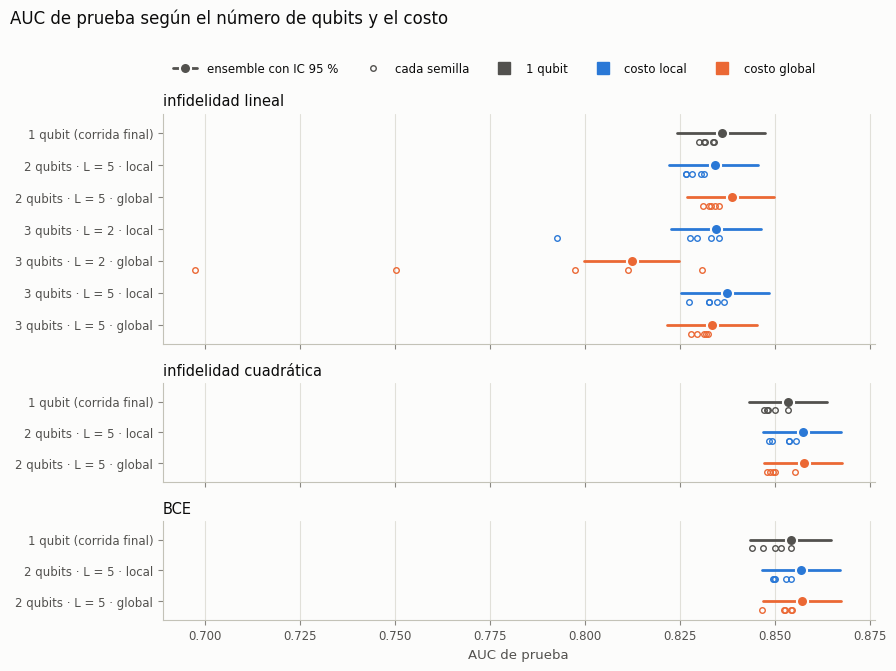

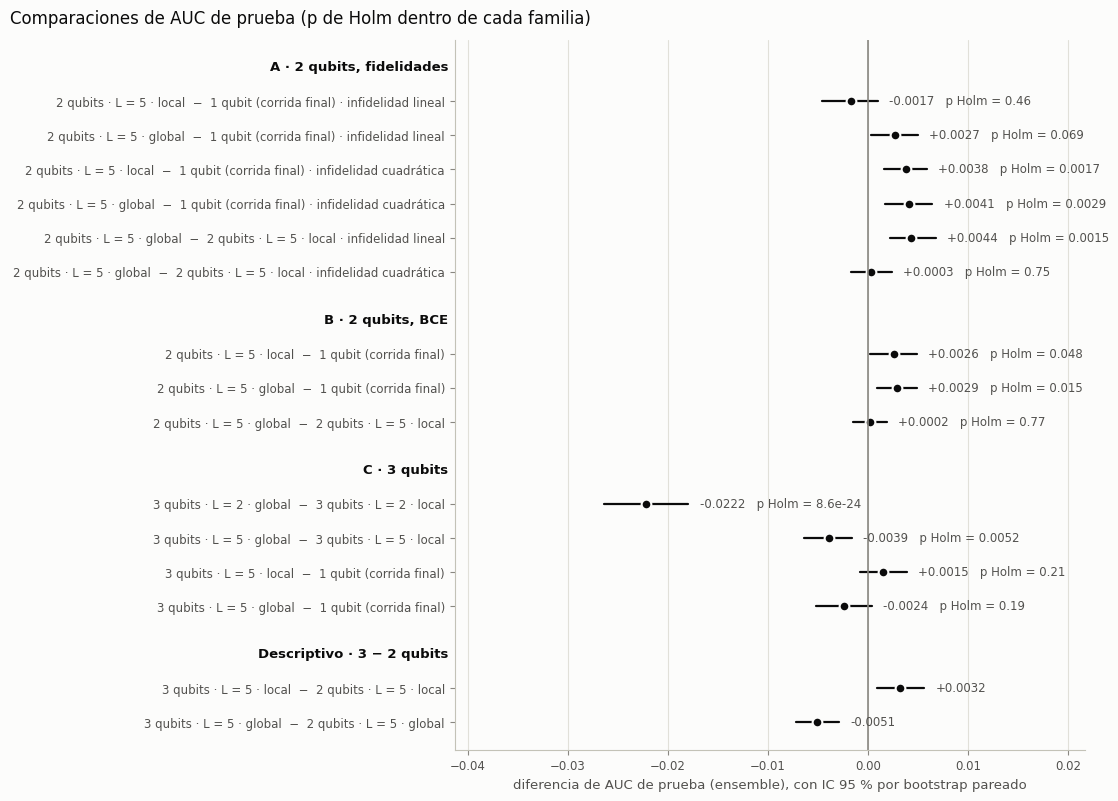

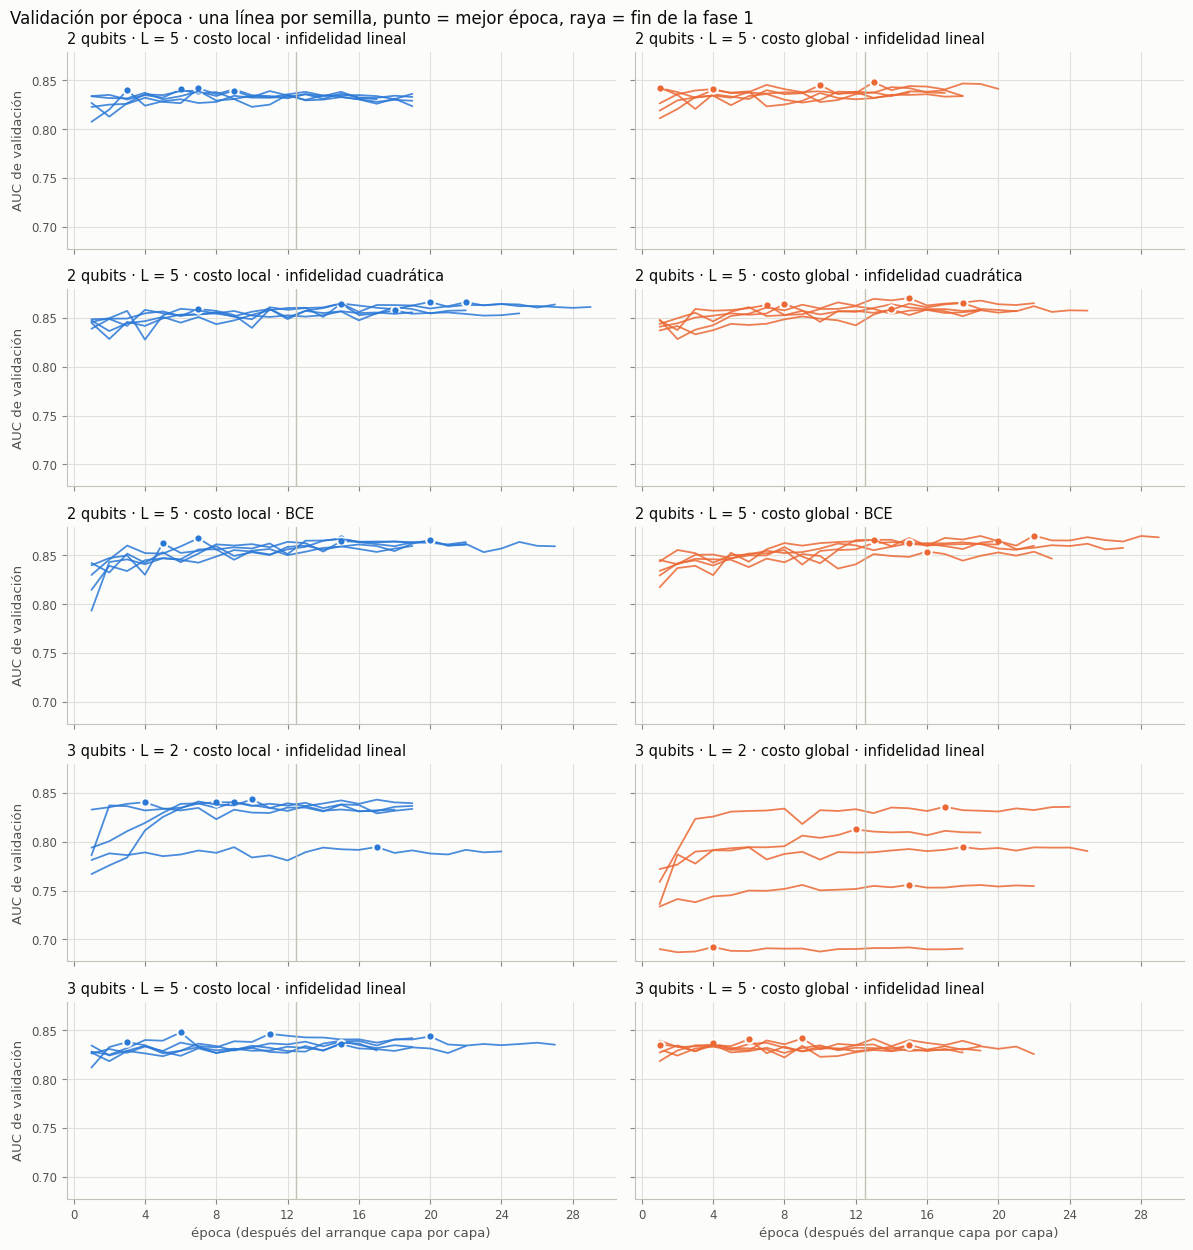

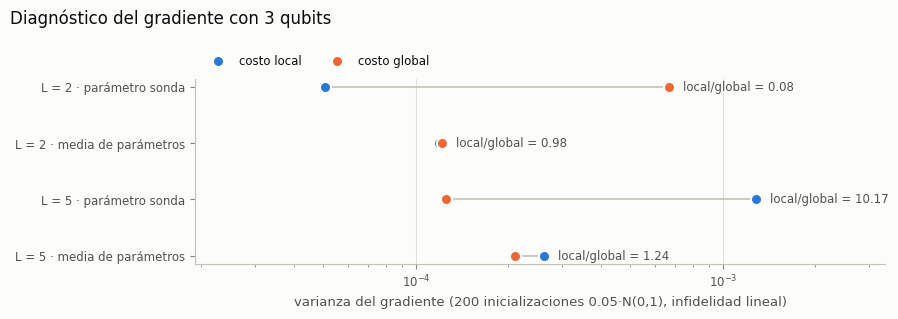

Gráficas guardadas en /content/drive/MyDrive/SUSY_DRU/qubits_2y3_v1/figuras


In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

TINTA, TINTA2, TENUE, REJILLA, EJE, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
COLOR = {"1q": TINTA2, "local": "#2a78d6", "global": "#eb6834"}   # azul / naranja (par validado para daltonismo)
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": EJE, "axes.linewidth": 0.8, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 10.5, "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False, "legend.fontsize": 8.5,
    "text.color": TINTA, "font.size": 9.5, "lines.linewidth": 1.6, "lines.solid_capstyle": "round",
})
AVISO = "\nPRUEBA RÁPIDA: los números no significan nada" if MODO == "rapido" else ""


def guardar(fig, archivo_png):
    fig.savefig(SALIDA / "figuras" / archivo_png, dpi=150, bbox_inches="tight")
    plt.show()


def color_de(clave):
    return COLOR["1q"] if clave.startswith("ref_") else COLOR[MODELOS[clave]["config"]["costo"]]


def etiqueta_corta(clave):
    c = MODELOS[clave]["config"]
    if clave.startswith("ref_"):
        return "1 qubit (corrida final)"
    return f"{c['n_qubits']} qubits · L = {c['capas']} · {c['costo']}"


# 1 · AUC de prueba por pérdida
grupos = {l: [f"ref_{l}"] + [config_id(c) for c in CONFIGURACIONES if c["perdida"] == l] for l in REF}
fig, axes = plt.subplots(len(grupos), 1, figsize=(9, 1.2 + 0.42 * sum(map(len, grupos.values()))), sharex=True,
                         gridspec_kw=dict(height_ratios=[len(v) for v in grupos.values()]))
for ax, (l, claves) in zip(axes, grupos.items()):
    for i, k in enumerate(claves):
        r = RESULTADOS.set_index("clave").loc[k]
        ax.plot([r.ic95_lo, r.ic95_hi], [i, i], color=color_de(k), lw=2)
        ax.plot(r.test_auc_ens, i, "o", color=color_de(k), ms=8, mec=FONDO, mew=1.5)
        sem = [roc_auc_score(YTE, p) for p in MODELOS[k]["prueba"]]
        ax.plot(sem, [i + 0.28] * len(sem), "o", ms=4, mfc="none", mec=color_de(k), mew=1)
    ax.set_yticks(range(len(claves)), [etiqueta_corta(k) for k in claves])
    ax.set_ylim(len(claves) - 0.4, -0.6)
    ax.grid(axis="y", visible=False)
    ax.set_title(NOMBRE_PERDIDA[l], loc="left")
axes[-1].set_xlabel("AUC de prueba")
leyenda = [Line2D([], [], color=TINTA2, marker="o", ms=8, mec=FONDO, mew=1.5, lw=2, label="ensemble con IC 95 %"),
           Line2D([], [], color=TINTA2, marker="o", ms=4, mfc="none", lw=0, label="cada semilla")]
leyenda += [Line2D([], [], color=COLOR[k], lw=0, marker="s", ms=8, label=t)
            for k, t in (("1q", "1 qubit"), ("local", "costo local"), ("global", "costo global"))]
axes[0].legend(handles=leyenda, loc="lower left", bbox_to_anchor=(0, 1.12), ncol=5)
fig.suptitle("AUC de prueba según el número de qubits y el costo" + AVISO, x=0.01, ha="left", fontsize=12, y=1.0)
fig.tight_layout()
guardar(fig, "auc_prueba.png")

# 2 · Comparaciones
fig, ax = plt.subplots(figsize=(11, 0.9 + 0.38 * (len(COMP) + COMP.familia.nunique())))
y_pos, etiquetas, fila_y = 0, [], []
for fam, g in COMP.groupby("familia", sort=False):
    ax.text(-0.01, y_pos, fam, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9.5,
            color=TINTA, fontweight="bold")
    y_pos += 1
    for r in g.itertuples():
        ax.plot([r.ic95_lo, r.ic95_hi], [y_pos, y_pos], color=TINTA, lw=1.6)
        ax.plot(r.dif_auc, y_pos, "o", color=TINTA, ms=7, mec=FONDO, mew=1.5)
        texto = f"{r.dif_auc:+.4f}" + ("" if np.isnan(r.p_holm) else f"   p Holm = {r.p_holm:.2g}")
        ax.annotate(texto, (r.ic95_hi, y_pos), xytext=(8, 0), textcoords="offset points", va="center", color=TINTA2,
                    fontsize=8.5)
        etiquetas.append(f"{etiqueta_corta(r.a)}  −  {etiqueta_corta(r.b)}"
                         + ("" if fam.startswith("B") or fam.startswith("C") or fam.startswith("Descr")
                            else f" · {NOMBRE_PERDIDA[MODELOS[r.a]['config']['perdida']]}"))
        fila_y.append(y_pos)
        y_pos += 1
    y_pos += 0.4
ax.axvline(0, color=TENUE, lw=1.2)
ax.set_yticks(fila_y, etiquetas)
ax.set_ylim(y_pos - 0.6, -0.8)
ax.grid(axis="y", visible=False)
ax.margins(x=0.45)
ax.set_xlabel("diferencia de AUC de prueba (ensemble), con IC 95 % por bootstrap pareado")
fig.suptitle("Comparaciones de AUC de prueba (p de Holm dentro de cada familia)" + AVISO, x=0.01, ha="left",
             fontsize=12)
fig.tight_layout()
guardar(fig, "comparaciones.png")

# 3 · Curvas de validación por época
filas_fig = [(2, 5, l) for l in ("infidelidad_lineal", "infidelidad_cuadratica", "bce")] + \
            [(3, 2, "infidelidad_lineal"), (3, 5, "infidelidad_lineal")]
fig, axes = plt.subplots(len(filas_fig), 2, figsize=(12, 1.2 + 2.3 * len(filas_fig)), sharex=True, sharey=True)
for (n, L, l), fila_ax in zip(filas_fig, axes):
    for ax, costo in zip(fila_ax, ("local", "global")):
        k = cid(n, L, costo, l)
        for z in MODELOS[k]["hist"]:
            ax.plot(z["hist_epoch"], z["hist_val_auc"], color=COLOR[costo], lw=1.3, alpha=0.85)
            mejor = z["meta"]["mejor_epoca"]
            if mejor:
                ax.plot(mejor, z["hist_val_auc"][mejor - 1], "o", color=COLOR[costo], ms=6, mec=FONDO, mew=1.5)
        ax.axvline(hp_de(dict(MODELOS[k]["config"], semilla=0)).stages[0][0] + 0.5, color=EJE, lw=1)
        ax.set_title(f"{n} qubits · L = {L} · costo {costo} · {NOMBRE_PERDIDA[l]}", loc="left")
for ax in axes[-1]:
    ax.set_xlabel("época (después del arranque capa por capa)")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes[:, 0]:
    ax.set_ylabel("AUC de validación")
fig.suptitle("Validación por época · una línea por semilla, punto = mejor época, raya = fin de la fase 1" + AVISO,
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
guardar(fig, "curvas_validacion.png")

# 4 · Diagnóstico del gradiente
fig, ax = plt.subplots(figsize=(9, 3.2))
filas_d = [(L, med) for L in (2, 5) for med in ("var_sonda", "var_media")]
for i, (L, med) in enumerate(filas_d):
    d = DIAG[DIAG.capas == L].set_index("costo")[med]
    ax.plot([d["local"], d["global"]], [i, i], color=EJE, lw=1.2)
    for costo in ("local", "global"):
        ax.plot(d[costo], i, "o", color=COLOR[costo], ms=8, mec=FONDO, mew=1.5)
    ax.annotate(f"local/global = {d['local'] / d['global']:.2f}", (max(d), i), xytext=(10, 0),
                textcoords="offset points", va="center", color=TINTA2, fontsize=8.5)
ax.set_xscale("log")
ax.set_yticks(range(len(filas_d)), [f"L = {L} · {'parámetro sonda' if m == 'var_sonda' else 'media de parámetros'}"
                                    for L, m in filas_d])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.margins(x=0.3)
ax.set_xlabel(f"varianza del gradiente ({N_INIT_DIAG} inicializaciones 0.05·N(0,1), infidelidad lineal)")
ax.legend(handles=[Line2D([], [], color=COLOR[k], marker="o", ms=8, mec=FONDO, mew=1.5, lw=0, label=f"costo {k}")
                   for k in ("local", "global")], loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.suptitle("Diagnóstico del gradiente con 3 qubits" + AVISO, x=0.01, ha="left", fontsize=12)
fig.tight_layout()
guardar(fig, "diagnostico_gradiente.png")
print("Gráficas guardadas en", SALIDA / "figuras")

## 10 · Resumen y equivalencias con la corrida final

En este notebook los modelos se llaman por lo que son. La equivalencia de las referencias de un qubit con los nombres de
la corrida final se guarda en `tablas/equivalencias_corrida_final.csv`, para usarla como leyenda en el informe.

| Archivo o carpeta | Contenido |
|---|---|
| `configuracion.json` | diseño del experimento, huella de los datos y versiones de la primera sesión |
| `verificacion_receta.json` | comprobación del paso 5 (la receta reproduce la corrida final) |
| `corridas/` | una corrida por archivo: parámetros, probabilidades de validación y de prueba, historial y resumen |
| `tablas/resultados_2q_3q.csv` | AUC de prueba (*ensemble* con IC 95 %, media ± sd por semilla) y validación, por modelo |
| `tablas/comparaciones_2q_3q.csv` | diferencias de AUC, IC 95 %, p de DeLong y p de Holm |
| `tablas/metricas_prueba_ensemble.csv` | AUC, AP, accuracy, precisión, recall, F1 y Brier del *ensemble* |
| `tablas/diagnostico_gradiente*.csv` | varianzas del gradiente y cocientes local/global del paso 7 |
| `figuras/` | las gráficas del paso 9 |

**Notas para interpretar**
- La primera R_Z de cada qubit en la primera capa actúa sobre |0⟩ y solo cambia una fase global: sus parámetros no hacen
  nada. Pasa igual con un qubit y en el repo.
- Pasar de 1 a 2 o 3 qubits multiplica los parámetros (70, 140, 210). Una diferencia de AUC puede venir de la capacidad del
  modelo y no solo del costo.
- La familia B (BCE) se añadió después de fijar las familias A y C, y se corrige aparte.
- El experimento no estaba pre-registrado y el conjunto de prueba ya se había usado: los resultados son exploratorios.

In [12]:
filas = []
for l, r in PUNTAJES_REF.items():
    fila = dict(modelo=nombre_ref(l), configuracion_corrida_final=r["nombre_repo"], archivo_puntajes=r["clave"])
    if r["nombre_repo"] in RES_CF.index:
        x = RES_CF.loc[r["nombre_repo"]]
        fila.update(corrida_final_auc_ensemble=x.test_auc_ens, corrida_final_ic95=f"[{x.ic95_lo:.4f}, {x.ic95_hi:.4f}]")
    filas.append(fila)
EQUIV = pd.DataFrame(filas)
EQUIV.to_csv(SALIDA / "tablas" / "equivalencias_corrida_final.csv", index=False)
print("Leyenda para el informe:")
display(EQUIV.style.hide(axis="index"))
print("Commit del repo:", COMMIT)
print("Funciones estadísticas usadas:", USO)
print("\nArchivos en", SALIDA)
for sub in ("", "corridas", "tablas", "figuras"):
    archivos = [f for f in (SALIDA / sub).iterdir() if f.is_file()]
    print(f"  {sub or '.':9s} {len(archivos):4d} archivos · {sum(f.stat().st_size for f in archivos) / 1e6:6.2f} MB")

Leyenda para el informe:


modelo,configuracion_corrida_final,archivo_puntajes,corrida_final_auc_ensemble,corrida_final_ic95
1 qubit · L = 5 · infidelidad lineal (corrida final),M3-lin,deda1e0abc4c,0.835983,"[0.8242, 0.8475]"
1 qubit · L = 5 · infidelidad cuadrática (corrida final),M3-cua,06520507efdc,0.853526,"[0.8432, 0.8637]"
1 qubit · L = 5 · BCE (corrida final),Z BCE,3613404333cc,0.854321,"[0.8434, 0.8646]"


Commit del repo: 6d8f93a Añade la corrida final del 7/11 y un notebook de Colab con PennyLane
Funciones estadísticas usadas: {'IC 95 %': 'repo (cf.auc_ci)', 'DeLong': 'repo (cf.delong; coincide con la del notebook)', 'Holm': 'repo (cf.holm; coincide con la del notebook)'}

Archivos en /content/drive/MyDrive/SUSY_DRU/qubits_2y3_v1
  .            2 archivos ·   0.01 MB
  corridas    50 archivos ·   2.80 MB
  tablas       6 archivos ·   0.01 MB
  figuras      4 archivos ·   0.72 MB
